# Exploratory Data Analysis (EDA)

## Customer Churn Prediction

### Objectives
- Analyze numerical features
- Analyze categorical features
- Study customer churn distribution
- Identify relationships between features and churn
- Detect outliers and unusual patterns
- Extract business insights

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [2]:
df = pd.read_csv(
    "../data/raw/Telco-Customer-Churn.csv"
)

print("Dataset Shape:", df.shape)

Dataset Shape: (7043, 21)


In [3]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [4]:
numeric_features = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = df.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numeric Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numeric Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges']

Categorical Features:
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']


In [5]:
for col in df.columns:
    print(
        f"{col}: {df[col].nunique()} unique values"
    )

customerID: 7043 unique values
gender: 2 unique values
SeniorCitizen: 2 unique values
Partner: 2 unique values
Dependents: 2 unique values
tenure: 73 unique values
PhoneService: 2 unique values
MultipleLines: 3 unique values
InternetService: 3 unique values
OnlineSecurity: 3 unique values
OnlineBackup: 3 unique values
DeviceProtection: 3 unique values
TechSupport: 3 unique values
StreamingTV: 3 unique values
StreamingMovies: 3 unique values
Contract: 3 unique values
PaperlessBilling: 2 unique values
PaymentMethod: 4 unique values
MonthlyCharges: 1585 unique values
TotalCharges: 6531 unique values
Churn: 2 unique values


In [6]:
churn_counts = df["Churn"].value_counts()

print(churn_counts)

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [7]:
churn_rates = (
    df["Churn"]
    .value_counts(normalize=True)
    .mul(100)
)

print(churn_rates)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [8]:
churn_summary = pd.DataFrame({
    "Count": churn_counts,
    "Percentage": churn_rates
})

churn_summary

,Count,Percentage
Churn,,
No,5174,73.463013
Yes,1869,26.536987


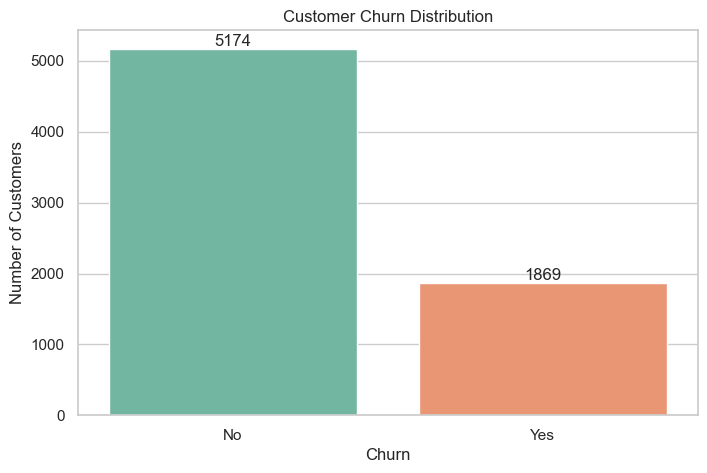

In [9]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

In [10]:
df[["tenure", "MonthlyCharges",
    "SeniorCitizen"]].describe().T

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00


In [11]:
total_charges = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

total_charges.describe()

count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.475000
75%      3794.737500
max      8684.800000
Name: TotalCharges, dtype: float64

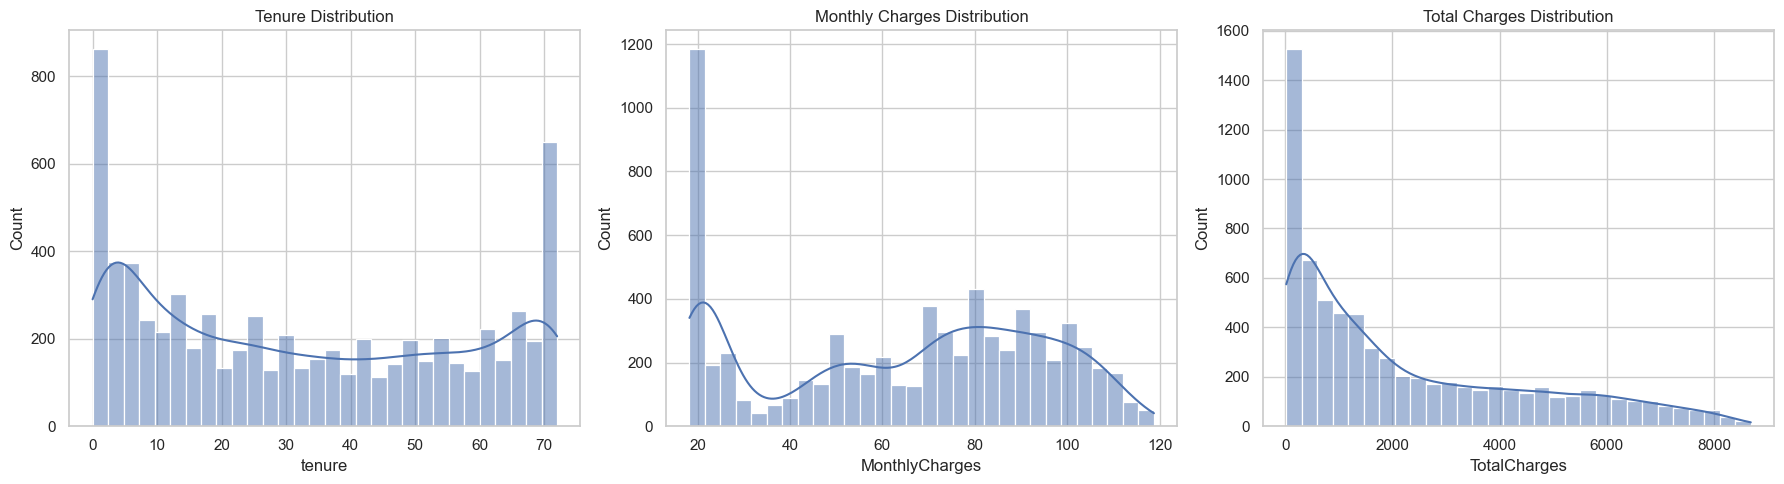

In [12]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

sns.histplot(
    df["tenure"],
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Tenure Distribution")

sns.histplot(
    df["MonthlyCharges"],
    bins=30,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Monthly Charges Distribution")

sns.histplot(
    total_charges.dropna(),
    bins=30,
    kde=True,
    ax=axes[2]
)
axes[2].set_title("Total Charges Distribution")

plt.tight_layout()
plt.show()

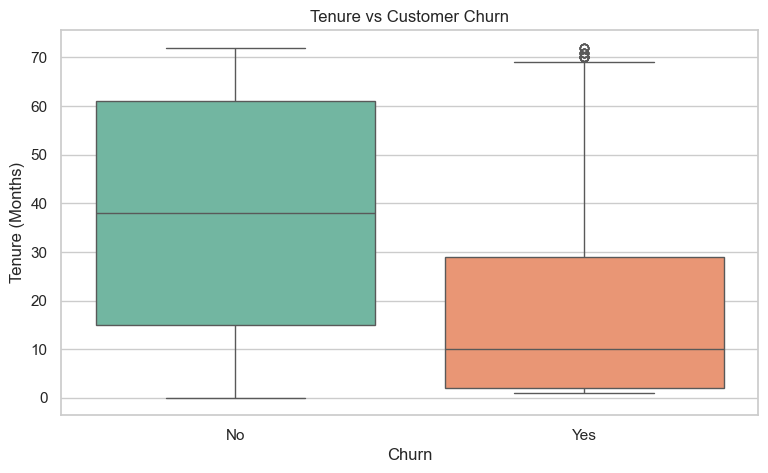

In [13]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Tenure vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

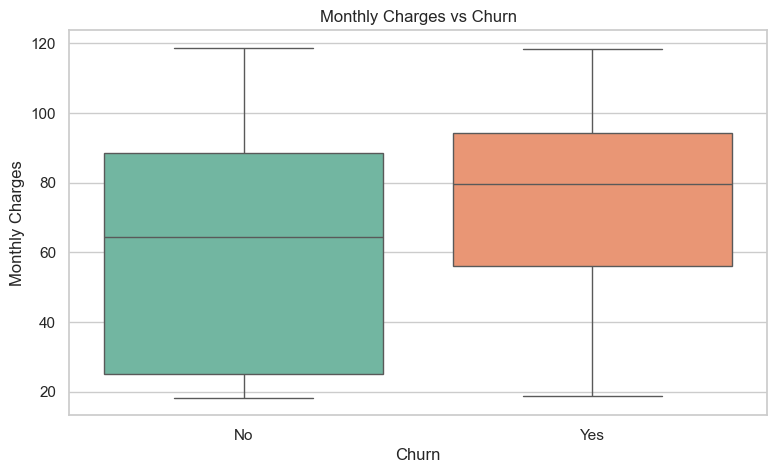

In [14]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

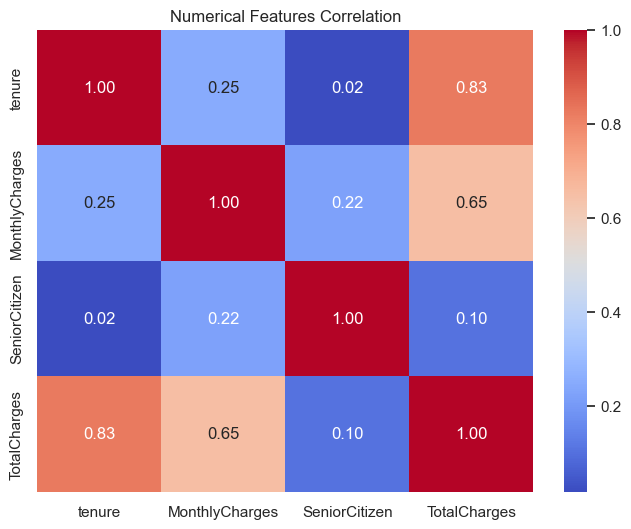

In [15]:
correlation_data = df[
    ["tenure", "MonthlyCharges", "SeniorCitizen"]
].copy()

correlation_data["TotalCharges"] = total_charges

correlation_matrix = correlation_data.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Numerical Features Correlation")

plt.show()